# 03 · What users complain about

**Author:** Mohamed Elsadany · data collected from Google Play on 28 Oct 2026

**My question:** what are the top complaint topics for each app, and what share of 1-star reviews does each cause?

**My approach:** I wrote keyword rules in Arabic, English and Franco (`src/topics.py`) that label each negative
review (1–2★) with zero, one or several of 12 topics. I kept the rules simple on purpose, so every label can be traced
back to the word that triggered it. I built the keyword lists from the most frequent words and phrases in the negative
reviews, and I use only reviews with 3+ words (`text_usable`) inside each app's full-coverage period.

In [1]:
import sys
import warnings
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from topics import TOPICS, TOPIC_LABELS, add_topics, matched_words  # noqa: E402

pd.set_option("display.max_colwidth", 160)
warnings.filterwarnings("ignore", message="obj.round has no effect")
IMAGES = ROOT / "images"
APPS = ["InstaPay", "Fawry", "Telda", "valU", "Vodafone Cash"]
INK, MUTED = "#1f1e1c", "#6b6a64"

df = pd.read_csv(ROOT / "data" / "processed" / "reviews_clean.csv", parse_dates=["at"])
df["content_clean"] = df["content_clean"].fillna("")
neg = df[df["in_full_coverage"] & df["text_usable"] & df["is_negative"]]
neg = add_topics(neg)
TOPIC_COLS = [f"topic_{k}" for k in TOPICS]
print(f"{len(neg):,} negative reviews with 3+ words, labeled with {len(TOPICS)} topics")

19,440 negative reviews with 3+ words, labeled with 12 topics


## 1. My 12 topics

In [2]:
pd.DataFrame([
    {"topic": k, "label": v[0], "arabic_keywords": len(v[1]), "english_franco_keywords": len(v[2]),
     "examples": ", ".join(v[1][:3] + v[2][:3]).replace("=", "")}
    for k, v in TOPICS.items()
])

,topic,label,arabic_keywords,english_franco_keywords,examples
0,app_not_working,"App won't open, crashes or is slow",50,48,"مش بيفتح, مبيفتحش, ميفتحش, crash, crashes, crashing"
1,failed_transaction,"Money deducted, transfer failed or stuck",80,31,"اتخصم, اتخصمت, خصم الفلوس, deducted, deduct, deducting"
2,login_verification,"Sign-up, login, verification or waiting list",58,40,"تسجيل, اسجل, سجلت, login, log in, logging in"
3,customer_service,Customer service unreachable or unhelpful,27,20,"خدمه العملاء, خدمه عملاء, خدمه الععملاء, customer service, customer support, customer care"
4,fees_interest,"Fees, charges or interest",12,13,"رسوم, عموله, مصاريف, fee, fees, charges"
5,card,"Card delivery, branches or ATM use",25,8,"الكارت, كارت, الكرت, card, cards, atm"
6,security_device,"Security block, unsupported phone or permissions",25,17,"خيارات المطور, وضع المطور, اعدادات المطور, hooked, rooted, root"
7,abroad,Can't use it from abroad,18,15,"خارج مصر, بره مصر, برا مصر, outside egypt, outside of egypt, abroad"
8,rejected_limits,Application rejected or limit too low,23,9,"اترفض, مرفوض, الرفض, rejected, reject, rejection"
9,fraud_accusation,Accuses the company of fraud or theft,16,16,"نصب, نصاب, حرامي, scam, scams, scammer"


## 2. How many reviews get a topic

About 30% of negative reviews get no topic. When I read them, most were general anger with nothing specific to
classify ("تطبيق فاشل", "worst app ever"). A quarter of reviews have two or more topics, for example
"money deducted and customer service never answered".

In [3]:
coverage = neg.groupby("app").agg(
    negative_reviews=("score", "size"),
    with_a_topic=("n_topics", lambda s: (s > 0).mean()),
    with_2plus_topics=("n_topics", lambda s: (s > 1).mean()),
).reindex(APPS)
coverage[["with_a_topic", "with_2plus_topics"]] = (coverage[["with_a_topic", "with_2plus_topics"]] * 100).round(1)
coverage

,negative_reviews,with_a_topic,with_2plus_topics
app,,,
InstaPay,5223,76.9,16.9
Fawry,7042,72.3,24.4
Telda,1798,63.5,19.0
valU,4841,62.8,18.0
Vodafone Cash,536,66.8,14.6


In [4]:
# A few reviews that got no topic, to see what the rules are missing
neg[neg["n_topics"] == 0].sample(8, random_state=3)[["app", "content"]]

,app,content
110,Fawry,فوري اختيار غلط نصيحه محدش يستثمر في فوري يومي
8998,Fawry,حد المعاملات غير مفهوم
62547,valU,It's consistently show me that I'm already registered but I'm not I don't know what is the issue.
66076,valU,ليه الابليكيشن يطلب صلاحية الوصول لتفاصيل شخصيه جدا علي التليفون طبعا دا يدل علي أنه حاجه مش كويسه
66793,valU,Very bad application and worst Coustmer service
62924,valU,اقسم بالله فلوسهم دخلت علي بيتي خربتوا هتفرح دلوقتي ساعه وهتتعب شهور وهتندم حسبي الله ونعم الوكيل الربا خراب بجد
61410,valU,ازاي اقسط من عاليه
71200,valU,اولا :ازاى مفيش لغه عربيه دا برنامج فى دوله عربيه. وثانيا : ازاى ندخل الاعدادات باللغه الانجليزيه وجوه تبقا عربى يبقا اولى كان كله يبقا عربى مش حته انجليزى ...


## 3. Complaint topics by app

This is the share of each app's negative reviews that mention each topic. A review can count toward several topics,
so the columns do not add up to 100%.

In [5]:
share = (neg.groupby("app")[TOPIC_COLS].mean().T * 100).reindex(columns=APPS)
share.index = [TOPIC_LABELS[c.replace("topic_", "")] for c in share.index]
share = share.loc[share.mean(axis=1).sort_values(ascending=False).index]
share.round(1)

app,InstaPay,Fawry,Telda,valU,Vodafone Cash
"App won't open, crashes or is slow",51.3,22.7,11.3,15.3,47.4
Customer service unreachable or unhelpful,14.2,34.4,17.6,22.3,9.7
"Sign-up, login, verification or waiting list",18.2,8.8,15.7,14.4,13.6
"Card delivery, branches or ATM use",2.0,15.9,24.6,2.9,5.4
Accuses the company of fraud or theft,0.7,6.4,7.5,9.0,3.7
"Fees, charges or interest",3.2,2.6,3.6,7.3,0.6
"Money deducted, transfer failed or stuck",1.2,10.1,2.5,0.9,1.7
Application rejected or limit too low,0.4,1.5,1.2,11.5,0.0
"Security block, unsupported phone or permissions",2.8,0.5,1.6,1.0,0.6
Can't use it from abroad,3.1,0.2,1.1,0.3,1.5


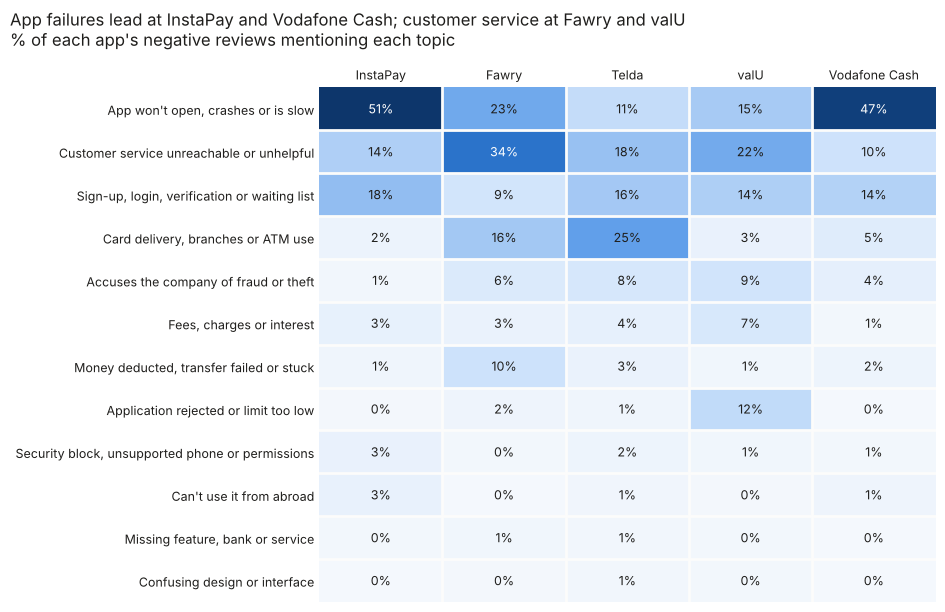

In [6]:
# Heatmap with a single blue scale: light = rare complaint, dark = common complaint.
cmap = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(9.5, 6.2))
im = ax.imshow(share.values, cmap=cmap, vmin=0, vmax=50, aspect="auto")
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=9,
                color="white" if v >= 28 else INK)
ax.set_xticks(range(len(APPS)), APPS, fontsize=9, color=INK)
ax.set_yticks(range(len(share)), share.index, fontsize=9, color=INK)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xticks([x - 0.5 for x in range(1, len(APPS))], minor=True)
ax.set_yticks([y - 0.5 for y in range(1, len(share))], minor=True)
ax.grid(which="minor", color="#fcfcfb", linewidth=2)
ax.tick_params(which="minor", length=0)
fig.suptitle("App failures lead at InstaPay and Vodafone Cash; customer service at Fawry and valU\n% of each app's negative reviews mentioning each topic", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
fig.savefig(IMAGES / "complaint_topics_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. What drives 1-star reviews

Here I take all 1-star reviews with 3+ words, from all five apps together, and measure the share that mentions each
topic. Fawry and InstaPay have the most reviews, so they weigh most in this total; section 3 shows each app separately.

In [7]:
one = neg[neg["score"] == 1]
drivers = (one[TOPIC_COLS].mean() * 100).sort_values(ascending=False)
drivers.index = [TOPIC_LABELS[c.replace("topic_", "")] for c in drivers.index]
print(f"{len(one):,} one-star reviews with 3+ words")
drivers.round(1).to_frame("% of 1-star reviews")

18,017 one-star reviews with 3+ words


,% of 1-star reviews
"App won't open, crashes or is slow",27.9
Customer service unreachable or unhelpful,24.6
"Sign-up, login, verification or waiting list",13.4
"Card delivery, branches or ATM use",9.3
Accuses the company of fraud or theft,5.9
"Money deducted, transfer failed or stuck",4.7
"Fees, charges or interest",3.9
Application rejected or limit too low,3.8
"Security block, unsupported phone or permissions",1.3
Can't use it from abroad,1.1


## 5. Each app's biggest problem, in users' words

In [8]:
# Reviews with crude insults still count in every number; I only leave them out of the printed examples.
CRUDE = ["عرص", "متناك", "خول", "=كس", "fuck", "shit"]
def printable(text):
    t = str(text).lower()
    return not any((w[1:] in t.split()) if w.startswith("=") else (w in t) for w in CRUDE)

top = share.idxmax()
for app in APPS:
    label = top[app]
    key = [k for k, v in TOPIC_LABELS.items() if v == label][0]
    g = neg[(neg["app"] == app) & neg[f"topic_{key}"] & (neg["word_count"] >= 8) & neg["content"].map(printable)]
    print(f"\n=== {app}: {label} ({share.loc[label, app]:.0f}% of negative reviews)")
    for _, r in g.sample(4, random_state=5).iterrows():
        print(f"  • [{', '.join(matched_words(r['content_clean'], key))}] {r['content'][:170]}")


=== InstaPay: App won't open, crashes or is slow (51% of negative reviews)
  • [خطا] عندي مشكلة إني بحاول أفعّل إنستا باي وببعت الرسالة لـ 4551، بس بيظهرلي (حدث خطأ) ومش بكمل التسجيل رغم إن معايا رصيد كافي.
  • [يقفل لوحده] البرنامج كام شغال عادي وبعدها كل ما احاول افتحه يقفل لوحده عملت كل الخطوات ونفس المشكلة
  • [not open] so bad not open please fix it urgently المشكلة مازلت موجودة
  • [عايز يفتح] مش عايز يفتح خااالص معرفش فجأه كده مسحته ونزلته تاني بردو مش عايز يفتح ياريت حل للمشكله



=== Fawry: Customer service unreachable or unhelpful (34% of negative reviews)
  • [خدمه العملاء] خدمه العملاء عندهم زباله وشويه بهايم شغاله في خدمه العملاء مش عارفه حاجه
  • [خدمه عملاء] خدمة عملاء ليست علي دراية بالخدمات اللتي تقدمها الشركة، لا يقدمون اي مساعدة او حلول محدودين جدا بنظام لا يسمح لهم بالمساعدة او تقديم اي خدمة للعملاء كل التجارب بالدفع معه
  • [خدمه العملاء] خدمة العملاء غير متعاونيين معاملة متأخرة اربعة ايام حتى الان ولا يوجد عندهم حلول مجرد ردود اليه
  • [خدمه العملاء, خدمه عملاء] تم ضياع اموالي بسبب اهمال شركة فوري وخدمة العملاء لشركة فوري جميع ممثلي خدمة عملاء الشركة لا تتعاون بحل المشكله وليس لديهم الخبره قمت بعمل ايداع عن طريق احد الماكينات وحد

=== Telda: Card delivery, branches or ATM use (25% of negative reviews)
  • [card] Only one star until I receive the card
  • [استلام البطاقه] لكي تحصل علي البطاقة ستنتظر كثير جدا وهذا امر سيئ برجاء من الشركة سرعة استلام البطاقة وعدم التاخير
  • [الكارت, الكرت] لسه تحت التجربه بس الكارت اتاخر جدآ أنا طالب الكرت لي اكثر م


=== valU: Customer service unreachable or unhelpful (22% of negative reviews)
  • [hotline] worst experience with an app ever, every step says i should activate my account and i never got any request for activation, i tried sending messages, emails and calling t
  • [customer service] worth app ever icant reach customer service and then block my account and reject my request without reason dont use
  • [الموظف] لما جيت افعل الحساب ف الفرع الموظف قالي الحساب اترفض تعالي بعد 3 شهور هفعلهولك علي طول هل الكلام ده صح؟ و ليه
  • [خدمه العملاء] طلبت تمويل شخصى بمبلغ كبير وتم رفضه واحاول اطلب مبلغ أقل لكن التطبيق بيطلب حذف الطلب السابق والطلب مش بيتحذف، تواصلت مع حسابكم فيس بوك والرد فيه آلى وطلبوا رقمى عشان يتوا

=== Vodafone Cash: App won't open, crashes or is slow (47% of negative reviews)
  • [لا يعمل] لو سمحت التطبيق لا يعمل له فترة كل اما ادخل على فودافون كاش لا يعمل نهائيا ليه فترة ومسحت التطبيق وحملته من جديد بأحدث اصدار مش عايز يخليني اكتب الباسوورد
  • [bug, not working] Awful app .

In [9]:
# The second-biggest problem for each app.
second = share.apply(lambda col: col.sort_values(ascending=False).index[1])
pd.DataFrame({"top_topic": top, "top_%": share.max().round(1),
              "second_topic": second, "second_%": [share.loc[second[a], a].round(1) for a in share.columns]})

,top_topic,top_%,second_topic,second_%
app,,,,
InstaPay,"App won't open, crashes or is slow",51.3,"Sign-up, login, verification or waiting list",18.2
Fawry,Customer service unreachable or unhelpful,34.4,"App won't open, crashes or is slow",22.7
Telda,"Card delivery, branches or ATM use",24.6,Customer service unreachable or unhelpful,17.6
valU,Customer service unreachable or unhelpful,22.3,"App won't open, crashes or is slow",15.3
Vodafone Cash,"App won't open, crashes or is slow",47.4,"Sign-up, login, verification or waiting list",13.6


## 6. How accurate are my rules?

**My spot check.** While building the rules I read random samples of 10–14 labeled reviews per topic, fixed the
keywords that caused wrong labels (for example "ربا" matching inside "الكهربا", "روت" inside "كروت", and "ميزه",
which is the Meeza card), and checked a fresh sample after each fix. On my last check, 8–10 of every 10 labels were
correct for each topic. Because I tuned the rules on similar samples, I treat this estimate as optimistic.

**Independent check.** The cell below saves 100 random negative reviews with their predicted topics to
`data/processed/topic_check_sample.csv`. I mark each one in `labels_correct` (yes / no) and write any missing topic
in `missing_topic`, then re-run the next cell to get an accuracy figure measured on reviews I did not tune on.

In [10]:
check_path = ROOT / "data" / "processed" / "topic_check_sample.csv"
if not check_path.exists():
    sample = neg.sample(100, random_state=2026)[["reviewId", "app", "score", "content", "topics"]].copy()
    sample["labels_correct"] = ""
    sample["missing_topic"] = ""
    sample.to_csv(check_path, index=False, encoding="utf-8-sig")
    print(f"Saved 100 reviews to check -> {check_path.relative_to(ROOT)}")
else:
    print("Check sample already exists; not overwriting your answers.")

Saved 100 reviews to check -> data/processed/topic_check_sample.csv


In [11]:
chk = pd.read_csv(check_path)
done = chk[chk["labels_correct"].astype(str).str.strip().str.lower().isin(["yes", "no", "y", "n"])]
if len(done):
    ok = done["labels_correct"].astype(str).str.strip().str.lower().isin(["yes", "y"]).mean()
    missing = done["missing_topic"].fillna("").astype(str).str.strip().ne("").mean()
    print(f"Checked {len(done)} reviews: labels correct for {ok:.0%}; a topic was missing in {missing:.0%}.")
else:
    print("Not checked yet: fill labels_correct in topic_check_sample.csv, then re-run this cell.")

Not checked yet: fill labels_correct in topic_check_sample.csv, then re-run this cell.


## 7. Saving the labeled reviews

In [12]:
out_cols = ["reviewId", "app", "score", "at", "lang_detected", "content", "topics", "n_topics"] + TOPIC_COLS
neg[out_cols].to_csv(ROOT / "data" / "processed" / "negative_reviews_topics.csv", index=False, encoding="utf-8-sig")
print(f"Saved {len(neg):,} labeled negative reviews -> data/processed/negative_reviews_topics.csv")

Saved 19,440 labeled negative reviews -> data/processed/negative_reviews_topics.csv


## What I found

*(Each app's full-coverage period; negative reviews with 3+ words.)*

1. **"The app doesn't work" is the #1 complaint:** it appears in **28% of 1-star reviews** across all apps,
   and in **51% of InstaPay's** and **47% of Vodafone Cash's** negative reviews.
2. **Customer service is a close #2 (25% of 1-star reviews)** and the top problem for **Fawry (34%)** and
   **valU (22%)**. Many of these reviews start with another problem and end with "and nobody answers".
3. **Failed or stuck transactions were smaller than I expected (about 5% of 1-star reviews)**, but they reach 10%
   for Fawry, where they are about bill payments, recharges and the Fawry card.
4. **Each app has its own problem:** Telda = the card (25%: fees, features, delivery) and the waiting list;
   valU = rejected applications and low limits (12%) plus interest and fees (7%);
   InstaPay = sign-up and SMS verification (18%) and not working from abroad (3%).
5. **valU gets the most fraud accusations (9% of its negative reviews)**, mostly about hidden fees and
   rejections after hours at a branch.

**Next:** in `04_sentiment.ipynb` I run Arabic and English sentiment models and look at reviews where the text and
the stars disagree.